# E-commerce Product Analytics — Purchase Funnel

## 1. Business Questions

This analysis focuses on the purchase funnel and answers the following questions:

- What share of users who visit the website go on to view a product, add it to the cart, start checkout and complete a purchase?
- At which step of the funnel are most users lost?
- How strongly does the measured conversion depend on the conversion window?
- Do the events in the dataset follow the order of a purchase journey, so that drop-offs between steps can be interpreted as friction?
- Does funnel conversion differ between countries, acquisition channels and subscription plans?

## 2. Funnel Metrics

- **Funnel steps:** Website Visit (`website_visit`) → View Product (`view_product_page`) → Add to Cart (`add_to_cart`) → Checkout Start (`checkout_start`) → Purchase (`checkout_complete`).
- **Sequential funnel:** a user reaches a step only if they have an event of that type *after* reaching the previous step. Each step is the user's first such event after the previous step.
- **Step conversion** — share of users at the previous step who reach the next step.
- **Conversion from visit** — share of users with a website visit who reach the step.
- **Overall conversion** — share of users with a website visit who complete a purchase through the funnel.
- **Conversion window** — the maximum time from the first website visit within which all steps must happen.

Definitions follow Amplitude's funnel analysis materials (see References).

## 3. Data

The analysis uses `events_clean` — the `events` table without the anomalous June–August 2023 sessions identified in `01_engagement.ipynb` (Section 4). Section 5 shows why this matters for the funnel. 972 of 1,000 users have at least one website visit and enter the funnel.

Main fields:

- `user_id` — identifies the user
- `event_time` — timestamp of the event
- `event_name` — type of event

**Observation window.** The last day in the data (18 August 2025) is only partly covered, so only events before the start of that day are used — the same boundary as in the other notebooks. Unless stated otherwise, the funnel has no time limit: a step counts if it happens at any time after the previous step. Section 6 compares this with 7-day and 30-day conversion windows. In a window of N days, a user is included only if the whole window is observed: first visit + N days must be earlier than 18 August 2025, the start of the partly covered last day. This is a conservative rule — a window that reaches the last, partly covered day is not used.

The logic of the sequential funnel follows an earlier version of this analysis. The query results are in `data/results/04_funnel/` and can be re-created with `python scripts/export_results.py`.

### Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'grid.alpha': 0.3
})

RESULTS = "../data/results/04_funnel/"


def add_conversion(df):
    """Add step conversion and conversion from the first step (%) to a funnel table."""
    df = df.copy()
    df["step_conversion_pct"] = (df["users"] / df["users"].shift(1) * 100).round(2)
    df["conversion_from_visit_pct"] = (df["users"] / df["users"].iloc[0] * 100).round(2)
    df["lost_users"] = (df["users"].shift(1) - df["users"]).astype("Int64")
    return df

## 4. Purchase Funnel

### Business Question

What share of users who visit the website reach each step of the purchase journey?

### SQL

[01_funnel.sql](../sql/04_funnel/01_funnel.sql)

Each step is built from the previous one. For example, the View Product step keeps, for every user who visited, the first `view_product_page` event after their first visit:

```sql
view_step AS (
    SELECT
        e.user_id,
        MIN(e.event_time) AS step_time
    FROM visit_step p
    INNER JOIN events_observed e
        ON e.user_id = p.user_id
    WHERE e.event_name = 'view_product_page'
      AND e.event_time > p.step_time
    GROUP BY e.user_id
)
```

The following steps repeat the same pattern for `add_to_cart`, `checkout_start` and `checkout_complete`.

### Results

In [2]:
funnel = add_conversion(pd.read_csv(RESULTS + "funnel_steps.csv"))

funnel

,step_order,step,users,step_conversion_pct,conversion_from_visit_pct,lost_users
0,1,Website Visit,972,NaN,100.00,<NA>
1,2,View Product,866,89.09,89.09,106
2,3,Add to Cart,722,83.37,74.28,144
3,4,Checkout Start,577,79.92,59.36,145
4,5,Purchase,439,76.08,45.16,138


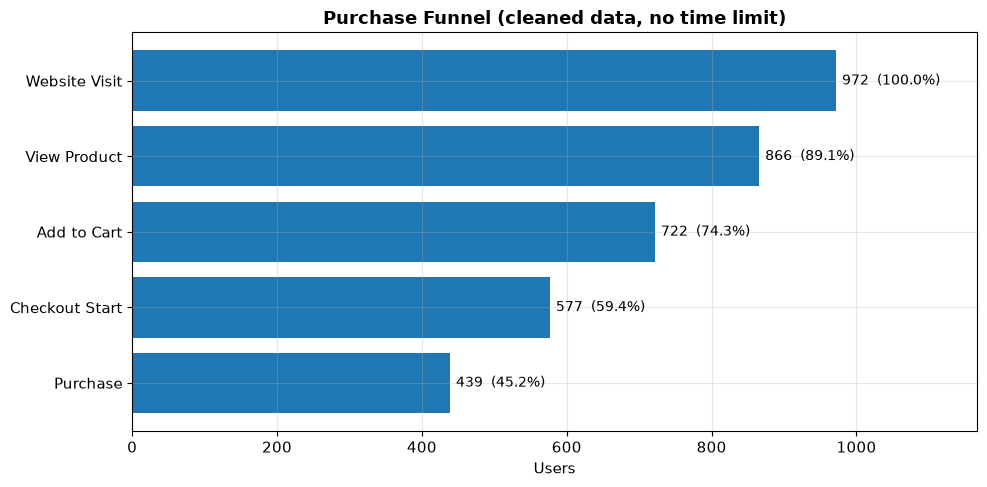

In [3]:
plt.figure(figsize=(10, 5))
bars = plt.barh(funnel["step"], funnel["users"], color="tab:blue")
plt.gca().invert_yaxis()

for bar, users, pct in zip(bars, funnel["users"], funnel["conversion_from_visit_pct"]):
    plt.text(bar.get_width() + 8, bar.get_y() + bar.get_height() / 2,
             f"{users}  ({pct:.1f}%)", va="center", fontsize=10)

plt.title("Purchase Funnel (cleaned data, no time limit)")
plt.xlabel("Users")
plt.xlim(0, funnel["users"].max() * 1.2)
plt.tight_layout()
plt.show()

### Finding

Of 972 users with a website visit, 866 (89.1%) later view a product, 722 (74.3%) add a product to the cart, 577 (59.4%) start checkout and 439 (45.2%) complete a purchase through the funnel.

Step conversion is 89.1% from visit to product view, 83.4% from view to cart, 79.9% from cart to checkout start and 76.1% from checkout start to purchase. Absolute user losses are relatively similar across the steps (106–145 users). However, the relative drop-off is largest between Checkout Start and Purchase (23.9%). Given the event-sequence issues identified in Section 7, this difference should not be interpreted as evidence of checkout friction.

Section 7 tests whether these drop-offs can be interpreted as friction in a purchase journey.

## 5. Impact of the June–August 2023 Anomaly

The anomalous sessions are exactly `website_visit` → `view_product_page` → `add_to_cart` → `session_end`, mostly attributed to users long before they sign up. In a sequential funnel without a time limit, they give these users the first three steps early, so any later `checkout_start` and `checkout_complete` events complete the funnel. The table compares the funnel on all data (`events`) and on cleaned data (`events_clean`).

In [4]:
funnel_all = add_conversion(pd.read_csv(RESULTS + "funnel_steps_all.csv"))

impact = funnel_all[["step", "users", "conversion_from_visit_pct"]].merge(
    funnel[["step", "users", "conversion_from_visit_pct"]],
    on="step", suffixes=("_all", "_clean")
)

impact

,step,users_all,conversion_from_visit_pct_all,users_clean,conversion_from_visit_pct_clean
0,Website Visit,991,100.00,972,100.00
1,View Product,950,95.86,866,89.09
2,Add to Cart,898,90.62,722,74.28
3,Checkout Start,775,78.20,577,59.36
4,Purchase,656,66.20,439,45.16


**Result:** on all data, 656 of 991 visitors (66.2%) complete the funnel; on cleaned data, 439 of 972 (45.2%). The anomaly inflates overall funnel conversion by about 21 percentage points. All results below use cleaned data.

## 6. Conversion Window

### Business Question

How does the measured conversion change if all funnel steps must happen within a limited time after the first visit?

### SQL

[02_conversion_window.sql](../sql/04_funnel/02_conversion_window.sql)

The query repeats the funnel for a 7-day window, a 30-day window and no time limit. In a window, a user is included only if the whole window is observed before the data end.

### Results

In [5]:
windows = pd.read_csv(RESULTS + "funnel_conversion_window.csv")

window_table = windows.pivot(index=["step_order", "step"], columns="conversion_window", values="users")
window_table = window_table[["7 days", "30 days", "No limit"]].droplevel("step_order")

conversion_from_visit = (window_table / window_table.iloc[0] * 100).round(2)

display(window_table)
display(conversion_from_visit.add_suffix(", % of visitors"))

conversion_window,7 days,30 days,No limit
step,,,
Website Visit,972,971,972
View Product,265,691,866
Add to Cart,54,398,722
Checkout Start,2,188,577
Purchase,0,83,439


conversion_window,"7 days, % of visitors","30 days, % of visitors","No limit, % of visitors"
step,,,
Website Visit,100.00,100.00,100.00
View Product,27.26,71.16,89.09
Add to Cart,5.56,40.99,74.28
Checkout Start,0.21,19.36,59.36
Purchase,0.00,8.55,45.16


For comparison, the next table shows how many visitors make **any** purchase within the window, without requiring the previous funnel steps. For each window, it uses the same visitors as the funnel above — those eligible for that window, whose whole window is observed (972 visitors for 7 days, 971 for 30 days) — so the two columns of each row share one denominator.

In [6]:
any_purchase = pd.read_csv(RESULTS + "funnel_window_any_purchase.csv").set_index("conversion_window")
any_purchase["purchase_through_funnel"] = window_table.loc["Purchase", any_purchase.index].values
any_purchase["any_purchase_pct"] = (any_purchase["visitors_with_any_purchase"] / any_purchase["eligible_visitors"] * 100).round(2)
any_purchase["through_funnel_pct"] = (any_purchase["purchase_through_funnel"] / any_purchase["eligible_visitors"] * 100).round(2)

any_purchase

,eligible_visitors,visitors_with_any_purchase,purchase_through_funnel,any_purchase_pct,through_funnel_pct
conversion_window,,,,,
7 days,972,297,0,30.56,0.00
30 days,971,725,83,74.67,8.55


### Finding

The conversion window changes the result completely. Within 7 days of the first visit, 27.3% of visitors view a product and none complete a purchase through the funnel. Within 30 days, 8.5% of visitors (83 of 971) complete a purchase through the funnel. Without a time limit, 45.2% do.

The 0% within 7 days refers to the full sequence of steps, not to purchases in general: 297 of 972 visitors (30.6%) make a purchase within 7 days of their first visit, and 725 of 971 (74.7%) within 30 days, but most of them do not go through view, cart and checkout start in this order within the window (none within 7 days, 83 of 725 within 30 days).

Purchase funnels are usually measured over short windows, such as a session, a day or a week. In this dataset, most funnel steps are reached weeks or months after the previous step, which an earlier version of this analysis also found. Section 7 examines why.

## 7. Do the Events Follow a Purchase Journey?

If the events in this dataset followed a purchase journey, a purchase would be expected to be preceded shortly by checkout start and add to cart, and checkout start would often be followed by a purchase. The two checks below test for these patterns.

The sequence check is event-level (it counts purchase events and event transitions), while the main funnel is user-level (it counts users). Both use the same cleaned data and observation window, but these metrics serve different purposes and should not be compared directly.

### SQL

[03_sequence_check.sql](../sql/04_funnel/03_sequence_check.sql)

### Check 1. Funnel steps shortly before a purchase

In [7]:
pd.read_csv(RESULTS + "funnel_sequence_before_purchase.csv")

,purchases,pct_with_checkout_start_24h_before,pct_with_add_to_cart_24h_before,pct_with_any_earlier_checkout_start
0,4517,4.7,5.7,78.6


Only 4.7% of purchase events have a `checkout_start` by the same user in the 24 hours before, and 5.7% have an `add_to_cart`. In a purchase journey, most purchases would be expected to have these steps shortly before.

### Check 2. The next event after checkout start

In [8]:
next_event = pd.read_csv(RESULTS + "funnel_next_event_after_checkout_start.csv")

next_event

,next_event,transitions,pct
0,notification_click,366,8.3
1,profile_view,360,8.1
2,feature_click,358,8.1
3,video_play,355,8.0
4,checkout_start,353,8.0
5,content_share,350,7.9
6,add_to_cart,343,7.7
7,app_open,342,7.7
8,search,337,7.6
9,settings_change,335,7.6


After `checkout_start`, the next event of the same user is any of the 13 event types with almost the same frequency (6.8–8.3% each; 1/13 ≈ 7.7%). `checkout_complete` is the next event in only 6.8% of cases.

### Finding

The observed event sequences are inconsistent with a typical purchase journey: the next event after checkout start is distributed almost evenly across all event types, and purchases are rarely preceded by checkout steps. This suggests that events may have been generated independently, although these two checks alone do not prove statistical independence of all events.

Therefore, funnel drop-offs cannot be reliably interpreted as checkout friction in this dataset. The sequential funnel mainly reflects how often events of the required types occur in the required order over a user's lifetime, and the step conversions in Section 4 and the long times to convert in Section 6 should not be read as friction points in the checkout process.

## 8. Funnel by Segment

### Business Question

Does funnel conversion differ between countries, acquisition channels and subscription plans?

### SQL

[04_segments.sql](../sql/04_funnel/04_segments.sql) — the funnel from Section 4, split by `users.country`, `acquisition_costs.acquisition_channel` and `subscriptions.plan` (only users with a subscription).

In [9]:
segments = pd.read_csv(RESULTS + "funnel_segments.csv")

for segment_type, data in segments.groupby("segment_type"):
    display(data.drop(columns="segment_type").set_index("segment").rename_axis(segment_type))

,visit_users,view_users,cart_users,checkout_start_users,purchase_users,overall_conversion_pct
Acquisition channel,,,,,,
Direct,116,97,85,66,57,49.14
Social Media,89,77,62,51,43,48.31
Email Campaign,96,87,70,62,46,47.92
Referral,107,93,78,60,50,46.73
Paid Search,117,111,87,70,54,46.15
Content Marketing,107,99,83,63,48,44.86
Organic Search,97,83,72,55,43,44.33
Partner,114,101,90,73,49,42.98
App Store,129,118,95,77,49,37.98


,visit_users,view_users,cart_users,checkout_start_users,purchase_users,overall_conversion_pct
Country,,,,,,
Japan,93,85,75,63,53,56.99
France,104,97,79,61,50,48.08
Mexico,96,86,70,55,46,47.92
Germany,110,100,84,66,52,47.27
Brazil,94,83,71,59,43,45.74
Australia,82,76,67,51,36,43.90
United States,95,85,72,53,41,43.16
Canada,101,85,65,54,42,41.58
United Kingdom,89,76,66,53,35,39.33


,visit_users,view_users,cart_users,checkout_start_users,purchase_users,overall_conversion_pct
Plan,,,,,,
Pro,88,81,69,57,43,48.86
Enterprise,37,36,30,23,18,48.65
Premium,123,106,90,75,59,47.97
Basic,197,174,148,125,89,45.18
Free,206,175,141,110,80,38.83


### Finding

Overall funnel conversion ranges from 37.98% (App Store) to 49.14% (Direct) across acquisition channels, from 37.96% (India) to 56.99% (Japan) across countries, and from 38.83% (Free) to 48.86% (Pro) across plans.

Segments differ in size (37–206 users), so a difference of several percentage points can come from a few users, and the plan segment includes only users with a subscription (651 of the 972 visitors), so plan conversion rates are not a comparison across all visitors. Given the event sequences described in Section 7, these differences are not interpreted as differences in user behaviour between segments.

## 9. Key Findings

- **Funnel conversion without a time limit is 45.2%.** Of 972 visitors, 89.1% view a product, 74.3% add to cart, 59.4% start checkout and 45.2% complete a purchase through the funnel; absolute losses are similar across the steps, and the relative drop-off is largest from checkout start to purchase (23.9%).
- **The anomaly strongly inflates the funnel.** On all data, overall conversion is 66.2% instead of 45.2%; the anomalous sessions give users the first three funnel steps long before they sign up.
- **The conversion window changes the result completely.** Overall conversion through the funnel is 0% within 7 days, 8.5% within 30 days and 45.2% without a time limit, although 30.6% of visitors make some purchase within 7 days.
- **The observed event sequences are inconsistent with a purchase journey.** Only 4.7% of purchase events have a checkout start in the 24 hours before, and after checkout start the next event is any event type with almost equal frequency. Drop-offs between steps therefore cannot be reliably interpreted as friction.
- **Segment differences are not interpreted.** Overall conversion ranges from about 38% to 57% across segments of 37–206 users.

## 10. Product Interpretation

In a real product, this funnel would point to where users are lost on the way to a purchase. In this dataset, the analysis mainly shows three methodological points:

1. **Data quality matters especially for sequential metrics.** The anomalous sessions add 21 percentage points to overall funnel conversion, because they supply the early funnel steps.
2. **A funnel needs a conversion window.** Without one, the funnel measures whether events eventually happen in the right order over years of data, and the result depends on how long users are observed.
3. **A funnel is only meaningful if events follow a journey.** Before interpreting drop-offs as friction, it is worth checking that steps actually follow each other in time. Here the observed sequences are inconsistent with a purchase journey, so the funnel cannot reliably identify friction points.

For a real dataset, the first step would be to validate event tracking: check that events are recorded in the order in which users act and that sessions are recorded correctly. Only then would it make sense to recompute a session-based or short-window funnel (for example, within 1 or 7 days) and to look at drop-offs by step and segment, rather than simply picking the step with the largest drop-off.

## 11. Next Questions

1. On a dataset with real user journeys, which step loses the most users within a session or a 7-day window?
2. How are the times between consecutive funnel steps distributed?
3. Do users who purchase without going through the funnel (directly after a visit) differ from users who complete all steps?
4. How does funnel conversion relate to customer acquisition cost and LTV by channel (`06_acquisition_monetization.ipynb`)?

## 12. Limitations

- The dataset is synthetic, and its observed event sequences are inconsistent with a purchase journey (Section 7).
- The main funnel has no time limit, so it depends on how long users are observed; the 7-day and 30-day windows show how strongly this affects the result.
- Each step uses the first event of that type after the previous step; a user is counted once, regardless of how many times they go through the steps.
- Segments are small (37–206 users), and the plan segment includes only users with a subscription.
- The analysis is observational and does not establish causal relationships.

## 13. References

Funnel definitions follow Amplitude's product analytics materials:

- Amplitude — [What Is Funnel Analysis? Definition, Examples, and Tools](https://amplitude.com/blog/funnel-analysis)
- Amplitude — [How to Build and Think About Your Product Funnel](https://amplitude.com/blog/product-funnel)
- Dataset — [adisomani/duckdb_product_analytics_tutorial](https://github.com/adisomani/duckdb_product_analytics_tutorial)